In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# --- Generate 500 automobile records ---
np.random.seed(33)
engine_size = np.random.uniform(1.2, 5.0, size=500)
horsepower = engine_size * 40 + np.random.normal(0, 20, size=500)
price = horsepower * 150 + engine_size * 2000 + np.random.normal(0, 3000, size=500)

df_cars = pd.DataFrame({'Engine_Size': engine_size, 'Horsepower': horsepower, 'Price': price})

X = df_cars[['Engine_Size', 'Horsepower']]
y = df_cars['Price']

model = LinearRegression()
model.fit(X, y)

print("Feature Coefficients:")
for col, coef in zip(X.columns, model.coef_):
    print(f"  {col}: {coef:.2f}")
print(f"R-squared value: {r2_score(y, model.predict(X)):.4f}")


Feature Coefficients:
  Engine_Size: 2086.67
  Horsepower: 149.83
R-squared value: 0.9161


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

# --- Generate 500 clinical observations ---
np.random.seed(34)
age = np.random.randint(20, 80, size=500)
bp = np.random.randint(90, 160, size=500)
outcome_prob = 1 / (1 + np.exp(-(0.05 * (130 - bp) + 0.03 * (50 - age))))
outcome = (np.random.rand(500) < outcome_prob).astype(int)

X = pd.DataFrame({'Age': age, 'BP': bp})
y = pd.Series(outcome)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
print(f"Overall Classification Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['Bad', 'Good']))


Overall Classification Accuracy: 0.6267

              precision    recall  f1-score   support

         Bad       0.62      0.42      0.50        67
        Good       0.63      0.80      0.70        83

    accuracy                           0.63       150
   macro avg       0.63      0.61      0.60       150
weighted avg       0.63      0.63      0.61       150



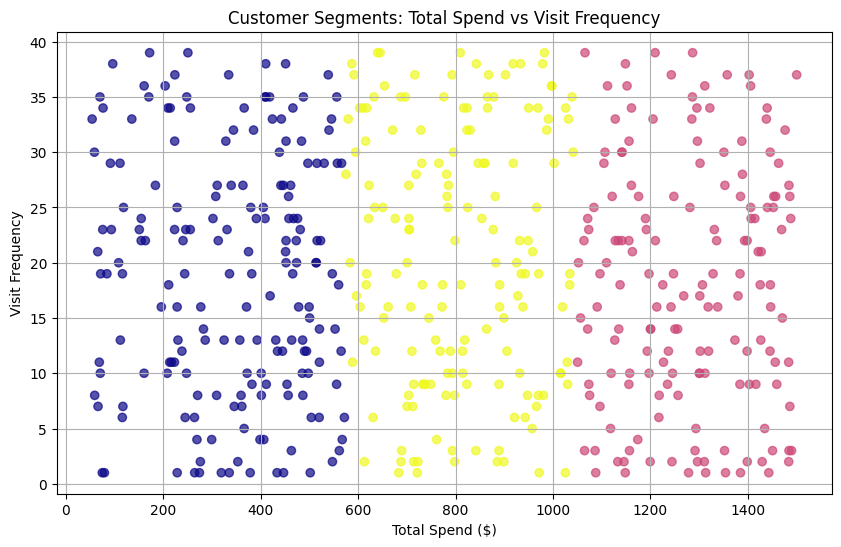

In [3]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# --- Generate 500 retail store records ---
np.random.seed(35)
total_spend = np.random.uniform(50, 1500, size=500)
visit_freq = np.random.randint(1, 40, size=500)

df_retail = pd.DataFrame({'Total_Spend': total_spend, 'Visit_Frequency': visit_freq})

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_retail['Segment'] = kmeans.fit_predict(df_retail)

plt.figure(figsize=(10, 6))
plt.scatter(df_retail['Total_Spend'], df_retail['Visit_Frequency'], c=df_retail['Segment'], cmap='plasma', alpha=0.7)
plt.title('Customer Segments: Total Spend vs Visit Frequency')
plt.xlabel('Total Spend ($)')
plt.ylabel('Visit Frequency')
plt.grid(True)
plt.show()


In [4]:
import pandas as pd
import numpy as np

# --- Generate 500 daily trading records ---
np.random.seed(36)
dates = pd.date_range(start="2022-01-01", periods=500)
prices = 100 + np.cumsum(np.random.normal(0, 2, size=500))
df_stock = pd.DataFrame({'Date': dates, 'Close_Price': prices})
df_stock.to_csv('stock_data.csv', index=False)

# Load and analyze
df_loaded = pd.read_csv('stock_data.csv')
std_dev = df_loaded['Close_Price'].std()
price_range = df_loaded['Close_Price'].max() - df_loaded['Close_Price'].min()

print(f"Stock Prices Analysis:")
print(f"  Standard Deviation (Volatility metric): {std_dev:.2f}")
print(f"  Total range of stock movement: ${price_range:.2f}")


Stock Prices Analysis:
  Standard Deviation (Volatility metric): 11.85
  Total range of stock movement: $58.35


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Generate 500 records ---
np.random.seed(37)
study_time = np.random.uniform(1.0, 15.0, size=500)
scores = (study_time * 5.5 + 20 + np.random.normal(0, 6, size=500)).clip(0, 100)

df_students = pd.DataFrame({'Study_Time': study_time, 'Exam_Score': scores})

correlation = df_students['Study_Time'].corr(df_students['Exam_Score'])
print(f"Pearson Correlation Coefficient: {correlation:.4f}")


Pearson Correlation Coefficient: 0.9686


In [6]:
import pandas as pd
import numpy as np

# --- Generate temperature readings for 5 cities ---
np.random.seed(38)
cities = ['New York', 'Los Angeles', 'Chicago', 'Miami', 'Seattle']
df_list = []

for city in cities:
    if city == 'Miami':
        temps = np.random.normal(loc=77, scale=5, size=365)
    elif city == 'Los Angeles':
        temps = np.random.normal(loc=68, scale=7, size=365)
    else:
        temps = np.random.normal(loc=52, scale=18, size=365)
    df_list.append(pd.DataFrame({'City': [city]*365, 'Temperature': temps}))

df_weather = pd.concat(df_list)

# Perform required analysis
stats_summary = df_weather.groupby('City')['Temperature'].agg(['mean', 'std', 'max', 'min'])
stats_summary['range'] = stats_summary['max'] - stats_summary['min']

print("Weather Metric Aggregates per City:")
display(stats_summary)


Weather Metric Aggregates per City:


,mean,std,max,min,range
City,,,,,
Chicago,52.070701,17.534632,110.615148,-12.296043,122.911191
Los Angeles,68.353410,6.941180,88.010550,50.698315,37.312235
Miami,76.792160,5.038840,91.881233,61.941971,29.939262
New York,53.407026,18.912370,107.346940,5.601877,101.745063
Seattle,53.085855,18.429118,114.600765,-0.590926,115.191691


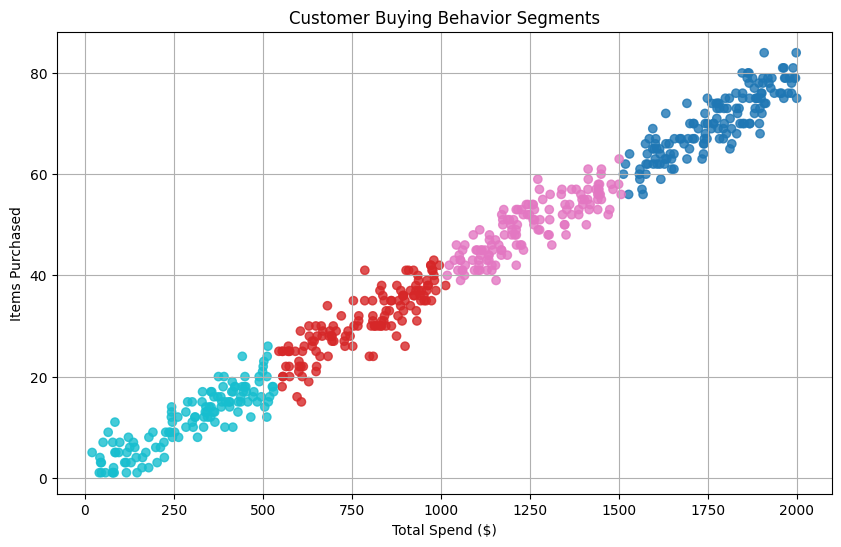

In [7]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# --- Generate 550 retail metrics ---
np.random.seed(39)
amount_spent = np.random.uniform(20, 2000, size=550)
items_purchased = (amount_spent * 0.04 + np.random.normal(0, 3, size=550)).clip(1).astype(int)

df_purchase = pd.DataFrame({'Amount_Spent': amount_spent, 'Items_Purchased': items_purchased})

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_purchase['Cluster'] = kmeans.fit_predict(df_purchase)

plt.figure(figsize=(10, 6))
plt.scatter(df_purchase['Amount_Spent'], df_purchase['Items_Purchased'], c=df_purchase['Cluster'], cmap='tab10', alpha=0.8)
plt.title('Customer Buying Behavior Segments')
plt.xlabel('Total Spend ($)')
plt.ylabel('Items Purchased')
plt.grid(True)
plt.show()


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Generate 500 custom soccer player records ---
np.random.seed(40)
positions = ['Forward', 'Midfielder', 'Defender', 'Goalkeeper']

names = [f"Player_{i}" for i in range(1, 501)]
ages = np.random.randint(18, 38, size=500)
assigned_positions = np.random.choice(positions, p=[0.25, 0.35, 0.30, 0.10], size=500)
goals = np.where(assigned_positions == 'Forward', np.random.randint(5, 30, size=500), np.random.randint(0, 8, size=500))
salaries = np.random.randint(10000, 250000, size=500)

df_soccer = pd.DataFrame({
    'Name': names,
    'Age': ages,
    'Position': assigned_positions,
    'Goals': goals,
    'Weekly_Salary': salaries
})

print("Top 5 Goal Scorers:")
display(df_soccer.nlargest(5, 'Goals')[['Name', 'Goals']])


Top 5 Goal Scorers:


,Name,Goals
157,Player_158,29
220,Player_221,29
223,Player_224,29
227,Player_228,29
306,Player_307,29
